# Deep Learning – Lab 7: End-to-End Deep Learning Challenge
## Predicting Bank Marketing Campaign Success

**Institution:** ENSIA – Higher National School of Artificial Intelligence  
**Course:** Deep Learning (Y4 / S7)  
**Lab Assignment:** Lab 7 – End-to-End Deep Learning Challenge  
**Dataset:** Bank Marketing (UCI Machine Learning Repository) – `bank-full.csv`

---

### Objectives
1. Explore and preprocess a real-world dataset containing heterogeneous features.
2. Establish a majority-class classifier and a Logistic Regression baseline.
3. Design, train, and optimize a Feed-Forward Neural Network using TensorFlow/Keras.
4. Address challenges associated with class imbalance and evaluate mitigation strategies.
5. Perform final evaluation on a held-out test set and formulate practical business decision recommendations.


---
## Setup & Environment

### 1. Import Required Packages
Import all packages required for data manipulation, visualization, modeling, evaluation, and neural network construction.


In [1]:
# General and Data Handling
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from IPython.display import display
import warnings
warnings.filterwarnings('ignore')

# Scikit-learn: Preprocessing, Pipelines & Selection
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_class_weight

# Scikit-learn: Baselines & Metrics
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

# TensorFlow & Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks, optimizers

# Reproducibility seeds
np.random.seed(42)
tf.random.set_seed(42)

# Plotting configuration
%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print(f"TensorFlow Version: {tf.__version__}")
print("All required packages imported successfully!")

# Display configuration
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)


TensorFlow Version: 2.21.0
All required packages imported successfully!


### 2. Load the Dataset
The dataset `bank-full.csv` contains 45,211 records and 17 columns (16 input features + 1 target variable `y`). The separator is semicolon (`;`).


In [2]:
# Load the dataset
data_path = 'bank-full.csv'
df = pd.read_csv(data_path, sep=';')

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()


Dataset Shape: 45211 rows, 17 columns


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


---
## Part I – Data Exploration

### 1.1 Dataset Structure & Summary Statistics
- Inspect column data types, missing values, and descriptive statistics for numerical and categorical features.


=== Dataset Information ===
<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 8.1 MB

Duplicate rows: 0

Explicit NaN counts:
age          0
job          0
marital      0
education    0
defa

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000



=== Categorical Features Summary ===


,job,marital,education,default,housing,loan,contact,month,poutcome,y
count,45211,45211,45211,45211,45211,45211,45211,45211,45211,45211
unique,12,3,4,2,2,2,3,12,4,2
top,blue-collar,married,secondary,no,yes,no,cellular,may,unknown,no
freq,9732,27214,23202,44396,25130,37967,29285,13766,36959,39922
top_freq_%,21.53%,60.19%,51.32%,98.20%,55.58%,83.98%,64.77%,30.45%,81.75%,88.30%



=== Unique Values per Categorical Feature ===


,Unique Count,Top Category (Share),All Unique Categories
job,12,blue-collar (21.5%),"management, technician, entrepreneur, blue-collar, unknown, retired, admin., services, self-employed, unemployed, housemaid, student"
marital,3,married (60.2%),"married, single, divorced"
education,4,secondary (51.3%),"tertiary, secondary, unknown, primary"
default,2,no (98.2%),"no, yes"
housing,2,yes (55.6%),"yes, no"
loan,2,no (84.0%),"no, yes"
contact,3,cellular (64.8%),"unknown, cellular, telephone"
month,12,may (30.4%),"may, jun, jul, aug, oct, nov, dec, jan, feb, mar, apr, sep"
poutcome,4,unknown (81.7%),"unknown, failure, other, success"
y,2,no (88.3%),"no, yes"



=== Distributions of Features with >= 3 Categories ===


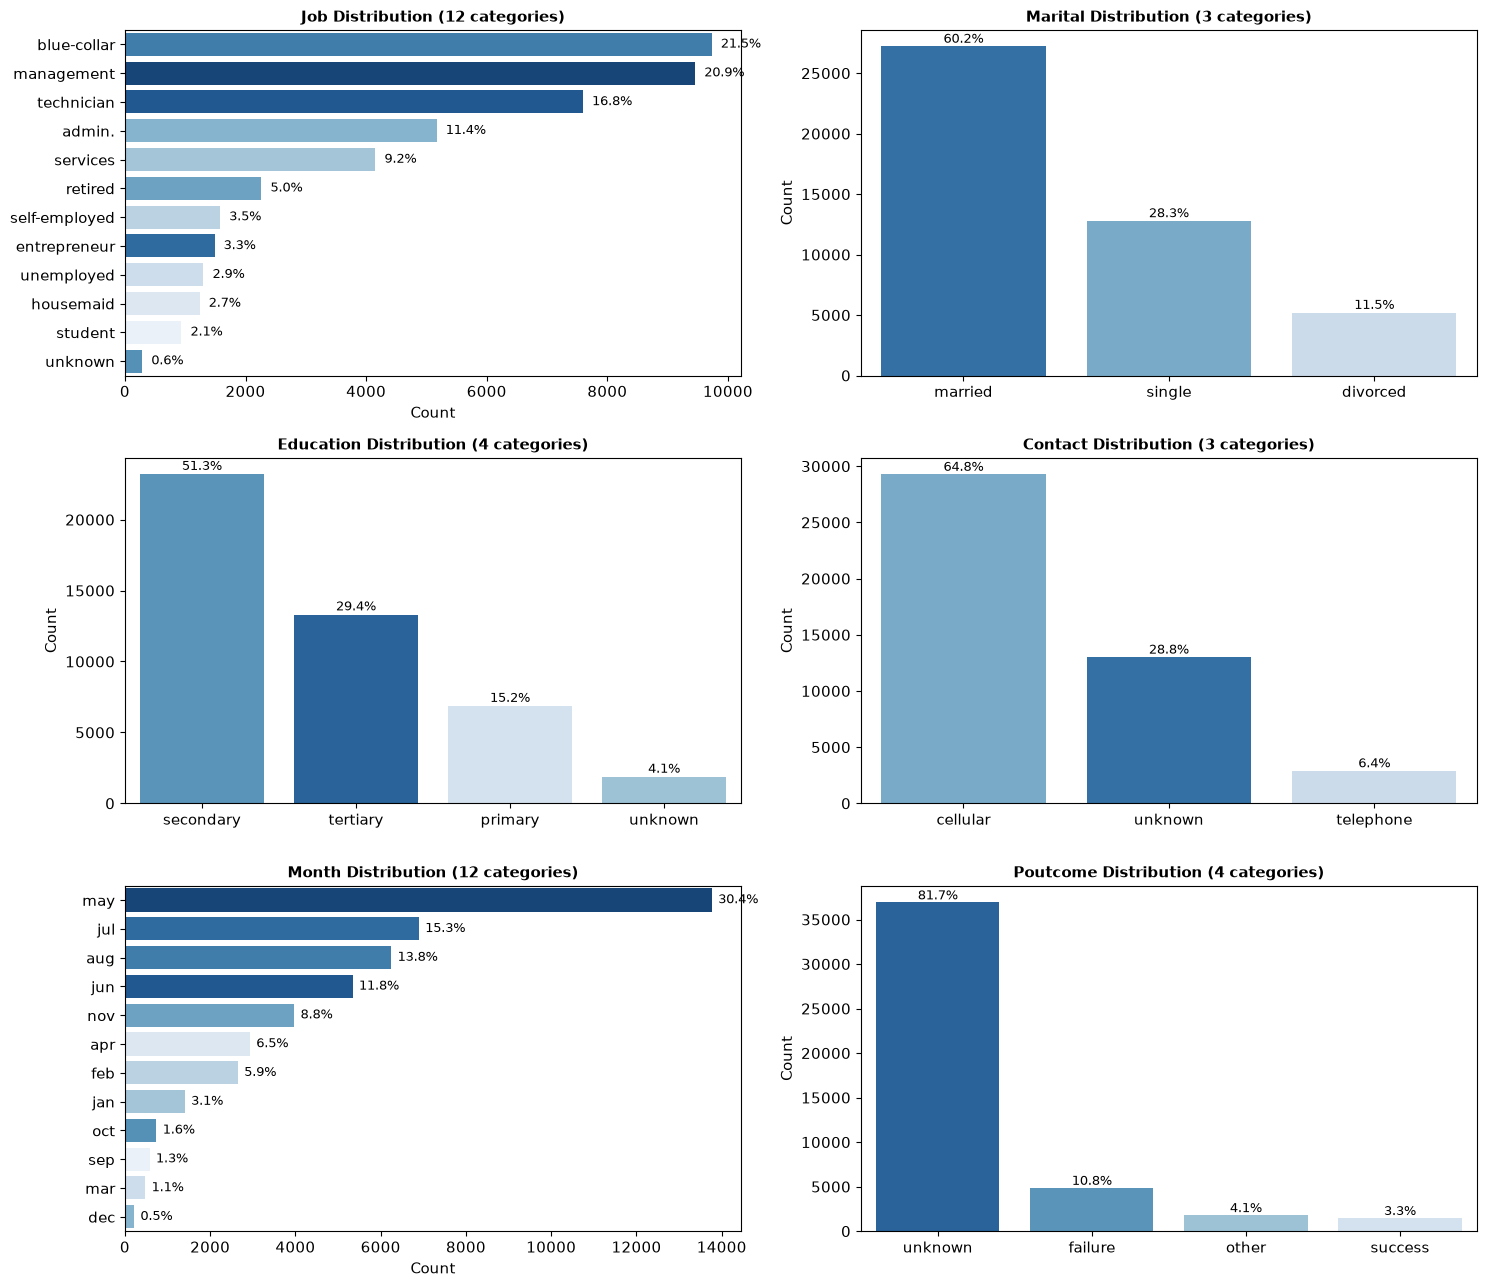

In [23]:
# Basic dataset dimensions and info
print("=== Dataset Information ===")
df.info()

# Check for duplicate rows
print(f"\nDuplicate rows: {df.duplicated().sum()}")

# Check for explicit missing values (NaN)
print(f"\nExplicit NaN counts:\n{df.isnull().sum()}")

# Check for disguised missing values ('unknown' placeholder)
print("\n'unknown' counts per column:")
unknown_counts = (df == "unknown").sum()
print(unknown_counts[unknown_counts > 0])

# Summary statistics for numerical features
print("\n=== Numerical Features Summary ===")
display(df.describe())

# Summary statistics for categorical features (with frequency percentage of top class)
print("\n=== Categorical Features Summary ===")
cat_summary = df.describe(include=["object", "string"]).copy()
cat_summary.loc["top_freq_%"] = (cat_summary.loc["freq"] / cat_summary.loc["count"] * 100).map("{:.2f}%".format)
display(cat_summary)

# Detailed breakdown listing all unique values per categorical feature (full width, no truncation)
print("\n=== Unique Values per Categorical Feature ===")
cat_cols = df.select_dtypes(include=["object", "string"]).columns
unique_summary = pd.DataFrame({
    "Unique Count": [df[col].nunique() for col in cat_cols],
    "Top Category (Share)": [f"{df[col].mode()[0]} ({df[col].value_counts(normalize=True).iloc[0]:.1%})" for col in cat_cols],
    "All Unique Categories": [", ".join(map(str, df[col].unique())) for col in cat_cols]
}, index=cat_cols)

with pd.option_context("display.max_colwidth", None, "display.width", 1000):
    display(unique_summary)

# Distributions of multi-category features (>= 3 unique values)
print("\n=== Distributions of Features with >= 3 Categories ===")
multi_cat_cols = [col for col in cat_cols if df[col].nunique() >= 3]

fig, axes = plt.subplots(3, 2, figsize=(15, 13))
axes = axes.flatten()

for idx, col in enumerate(multi_cat_cols):
    ax = axes[idx]
    order = df[col].value_counts().index
    total = len(df)
    
    if col in ["job", "month"]:
        # Horizontal bar plot for features with 12 categories
        sns.countplot(data=df, y=col, order=order, ax=ax, palette="Blues_r", hue=col, legend=False)
        ax.set_title(f"{col.capitalize()} Distribution ({df[col].nunique()} categories)", fontsize=11, fontweight="bold")
        ax.set_xlabel("Count")
        ax.set_ylabel("")
        for p in ax.patches:
            w = p.get_width()
            ax.annotate(f"{w/total:.1%}", (w + 150, p.get_y() + p.get_height() / 2), va="center", fontsize=9)
    else:
        # Vertical bar plot for features with 3-4 categories
        sns.countplot(data=df, x=col, order=order, ax=ax, palette="Blues_r", hue=col, legend=False)
        ax.set_title(f"{col.capitalize()} Distribution ({df[col].nunique()} categories)", fontsize=11, fontweight="bold")
        ax.set_xlabel("")
        ax.set_ylabel("Count")
        for p in ax.patches:
            h = p.get_height()
            ax.annotate(f"{h/total:.1%}", (p.get_x() + p.get_width() / 2, h + 300), ha="center", fontsize=9)

plt.tight_layout()
plt.show()


### 1.2 Exploratory Data Analysis & Visualizations
- Explore feature distributions, correlations, and relationships with the target variable `y`.


=== 1. Categorical Feature Discriminative Power Ranking ===


,Feature,Categories,Min Rate,Max Rate,Spread (%),Best Category,Worst Category
0,poutcome,4,9.2%,64.7%,55.6%,success (64.7%),unknown (9.2%)
1,month,12,6.7%,52.0%,45.3%,mar (52.0%),may (6.7%)
2,job,12,7.3%,28.7%,21.4%,student (28.7%),blue-collar (7.3%)
3,contact,3,4.1%,14.9%,10.8%,cellular (14.9%),unknown (4.1%)
4,housing,2,7.7%,16.7%,9.0%,no (16.7%),yes (7.7%)
5,education,4,8.6%,15.0%,6.4%,tertiary (15.0%),primary (8.6%)
6,loan,2,6.7%,12.7%,6.0%,no (12.7%),yes (6.7%)
7,default,2,6.4%,11.8%,5.4%,no (11.8%),yes (6.4%)
8,marital,3,10.1%,14.9%,4.8%,single (14.9%),married (10.1%)



=== 2. Numerical Feature Comparison & Skewness Profile ===


,Feature,Median (No),Median (Yes),Mean (No),Mean (Yes),Correlation (r),Skewness
0,duration,164.0,426.0,221.2,537.3,+0.395,3.14
1,pdays,-1.0,-1.0,36.4,68.7,+0.104,2.62
2,previous,0.0,0.0,0.5,1.2,+0.093,41.85
3,campaign,2.0,2.0,2.8,2.1,-0.073,4.90
4,balance,417.0,733.0,1303.7,1804.3,+0.053,8.36
5,day,16.0,15.0,15.9,15.2,-0.028,0.09
6,age,39.0,38.0,40.8,41.7,+0.025,0.68


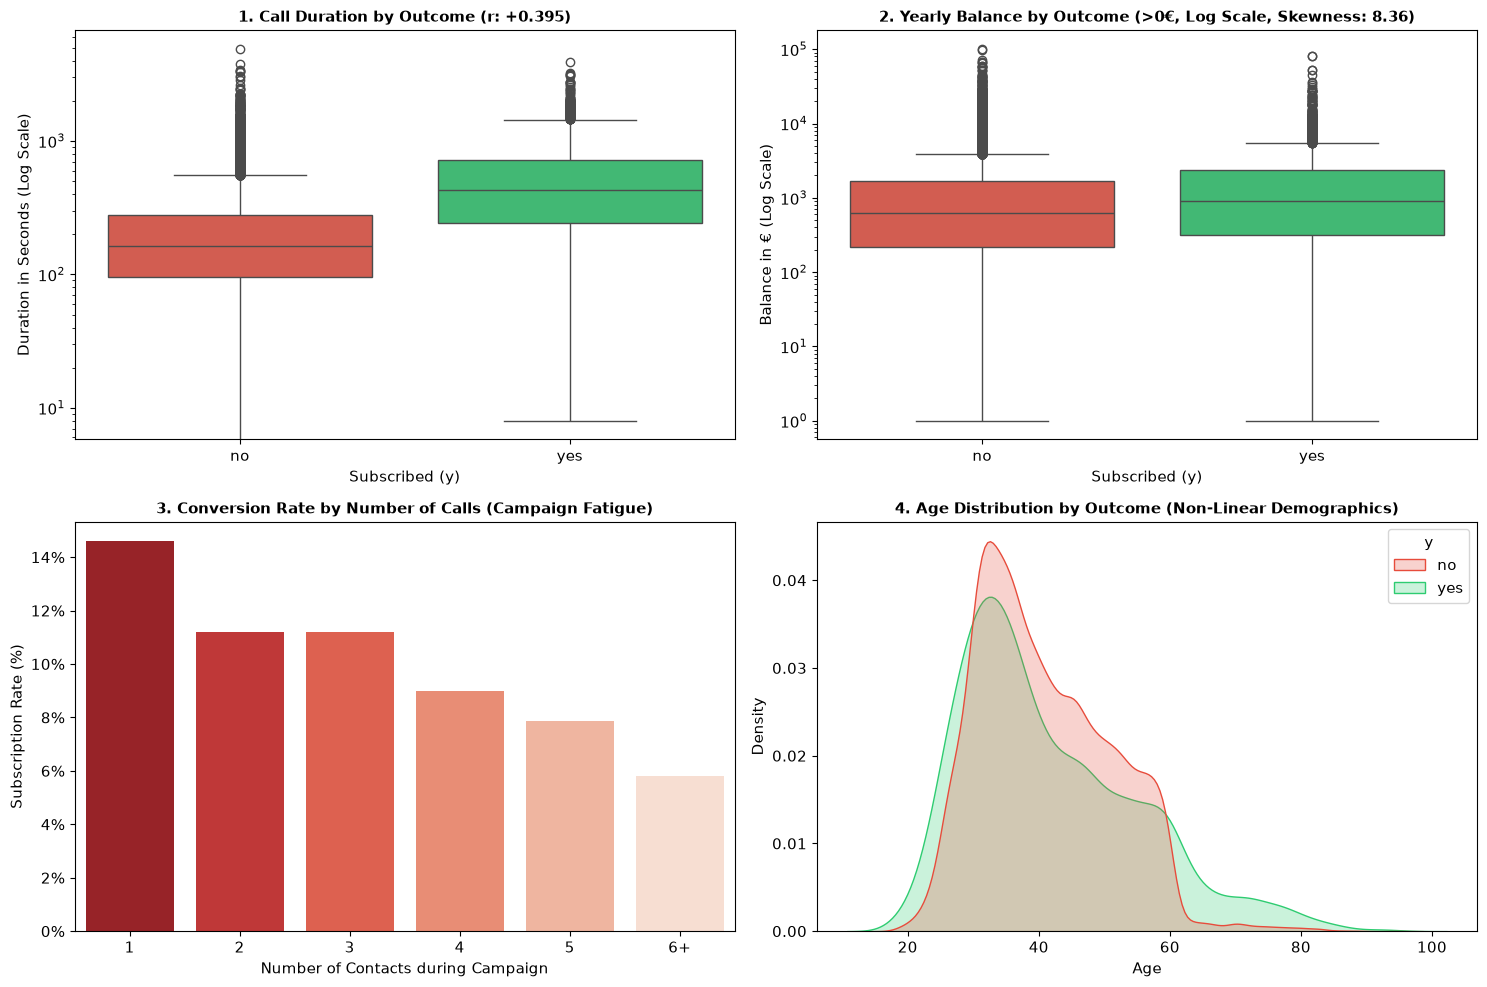

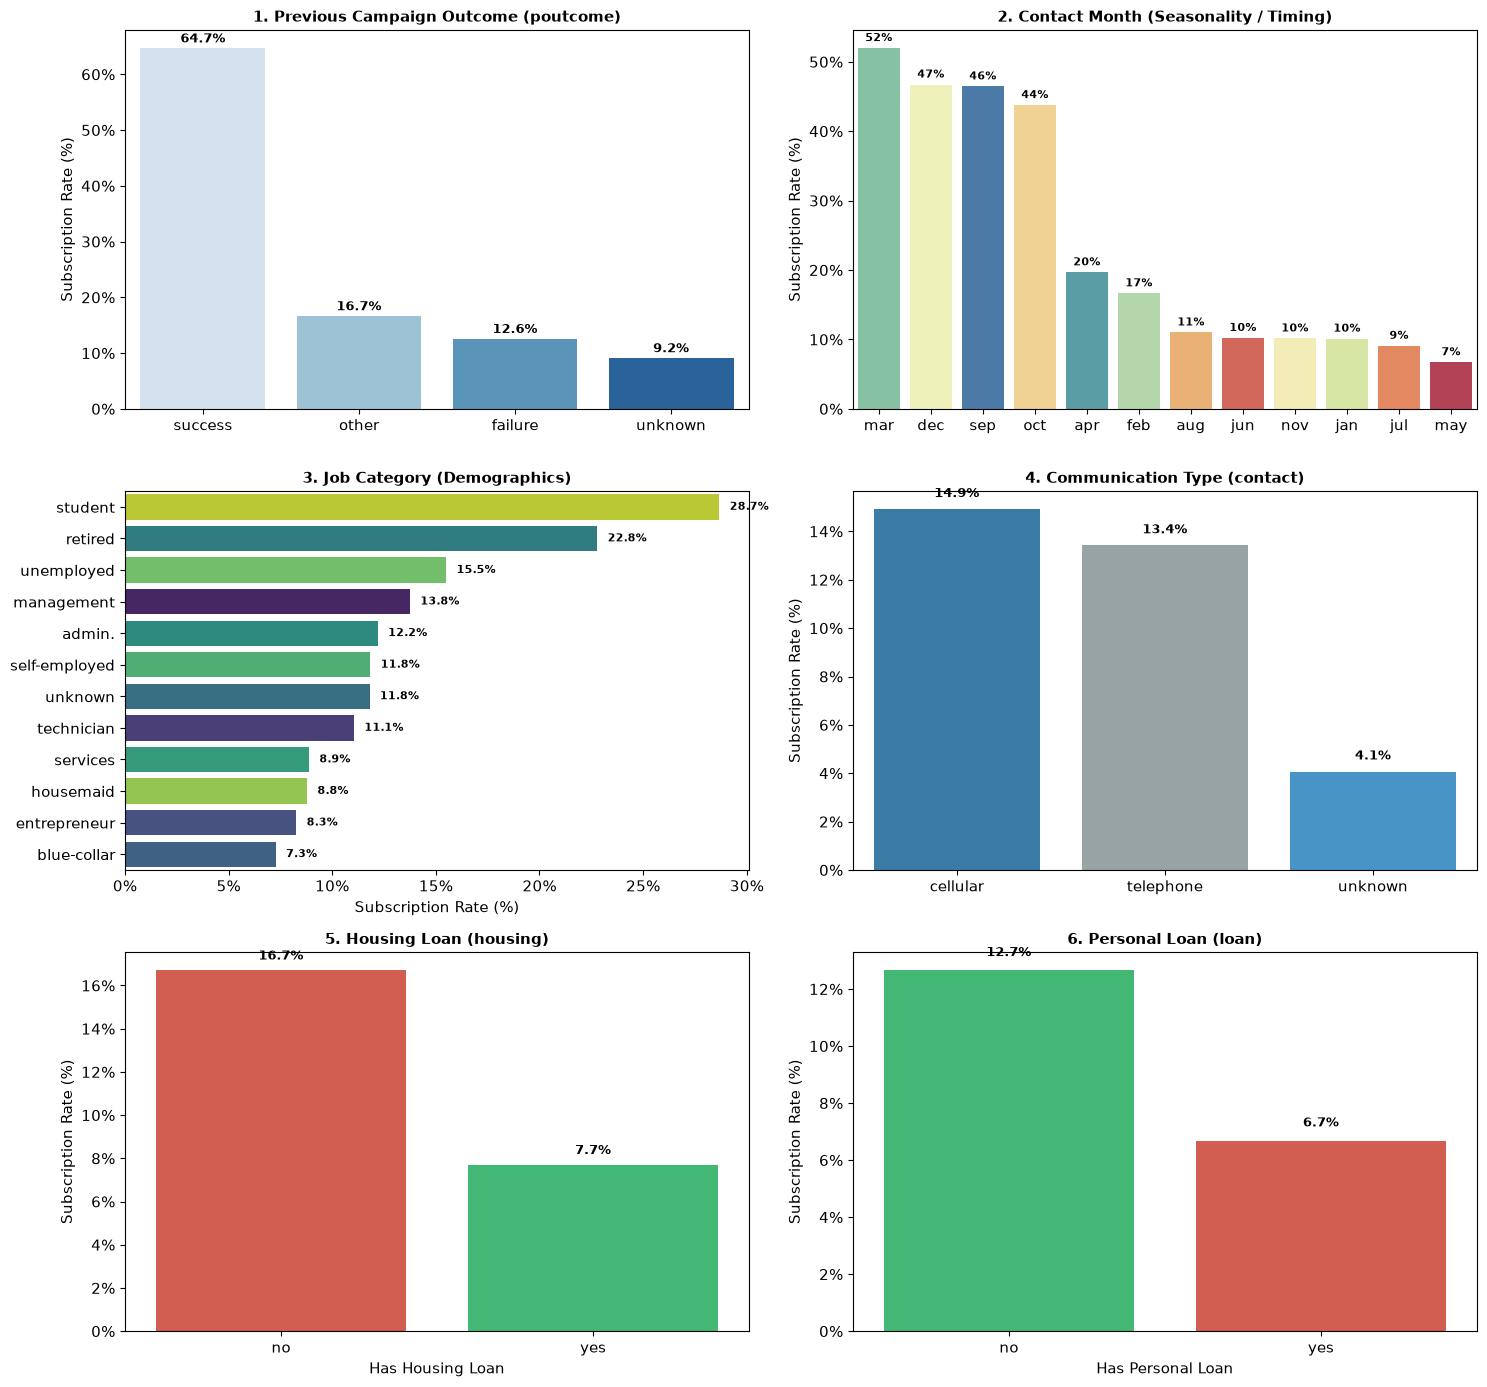

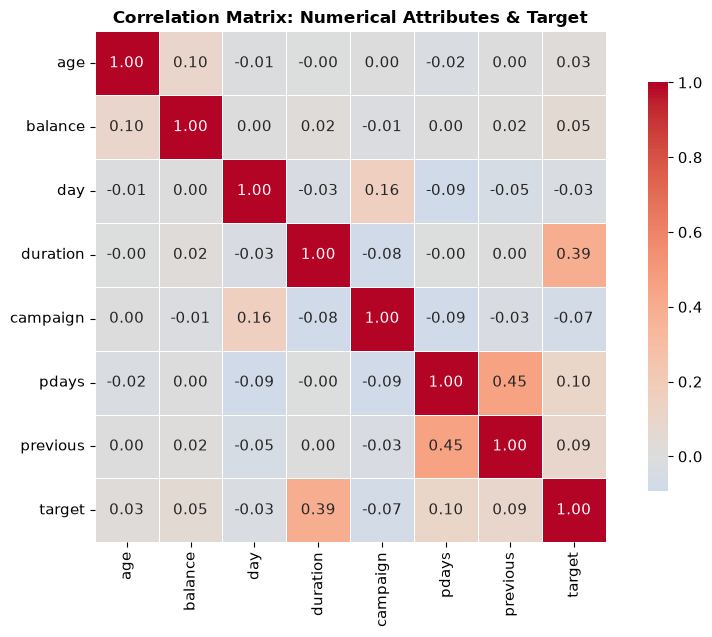

In [24]:
# Temporary binary target for EDA correlations and conversion rates
df["target"] = (df["y"] == "yes").astype(int)

# ===================================================================
# Step 1: Quantitative Screening of Features
# ===================================================================

# A. Categorical Feature Screening (Conversion Rate Spread: Max - Min)
print("=== 1. Categorical Feature Discriminative Power Ranking ===")
cat_cols = [c for c in df.select_dtypes(include=["object", "string"]).columns if c != "y"]
cat_records = []
for col in cat_cols:
    rates = df.groupby(col)["target"].mean()
    spread = rates.max() - rates.min()
    cat_records.append({
        "Feature": col,
        "Categories": df[col].nunique(),
        "Min Rate": f"{rates.min():.1%}",
        "Max Rate": f"{rates.max():.1%}",
        "Spread (Max - Min)": spread,
        "Spread (%)": f"{spread:.1%}",
        "Best Category": f"{rates.idxmax()} ({rates.max():.1%})",
        "Worst Category": f"{rates.idxmin()} ({rates.min():.1%})"
    })
cat_ranking_df = pd.DataFrame(cat_records).sort_values(by="Spread (Max - Min)", ascending=False)
cat_ranking_df.drop(columns=["Spread (Max - Min)"], inplace=True)
cat_ranking_df.reset_index(drop=True, inplace=True)
display(cat_ranking_df)

# B. Numerical Feature Screening (Correlation, Class Medians, Means & Skewness)
print("\n=== 2. Numerical Feature Comparison & Skewness Profile ===")
num_cols = ["duration", "balance", "age", "day", "campaign", "pdays", "previous"]
num_records = []
for col in num_cols:
    med_no = df[df["target"] == 0][col].median()
    med_yes = df[df["target"] == 1][col].median()
    mean_no = df[df["target"] == 0][col].mean()
    mean_yes = df[df["target"] == 1][col].mean()
    corr = df[col].corr(df["target"])
    skew = df[col].skew()
    num_records.append({
        "Feature": col,
        "Median (No)": med_no,
        "Median (Yes)": med_yes,
        "Mean (No)": f"{mean_no:.1f}",
        "Mean (Yes)": f"{mean_yes:.1f}",
        "Correlation (r)": f"{corr:+.3f}",
        "abs_corr": abs(corr),
        "Skewness": f"{skew:.2f}"
    })
num_ranking_df = pd.DataFrame(num_records).sort_values(by="abs_corr", ascending=False)
num_ranking_df.drop(columns=["abs_corr"], inplace=True)
num_ranking_df.reset_index(drop=True, inplace=True)
display(num_ranking_df)

# ===================================================================
# Step 2: Visualizations of Key Numerical Features vs Target
# ===================================================================
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Duration (Log-scale boxplot)
sns.boxplot(data=df, x="y", y="duration", hue="y", ax=axes[0, 0],
            palette=["#e74c3c", "#2ecc71"], legend=False)
axes[0, 0].set_yscale("log")
axes[0, 0].set_title("1. Call Duration by Outcome (r: +0.395)", fontsize=11, fontweight="bold")
axes[0, 0].set_xlabel("Subscribed (y)")
axes[0, 0].set_ylabel("Duration in Seconds (Log Scale)")

# 2. Balance (Log-scale boxplot for positive balances)
df_pos_bal = df[df["balance"] > 0].copy()
sns.boxplot(data=df_pos_bal, x="y", y="balance", hue="y", ax=axes[0, 1],
            palette=["#e74c3c", "#2ecc71"], legend=False)
axes[0, 1].set_yscale("log")
axes[0, 1].set_title("2. Yearly Balance by Outcome (>0€, Log Scale, Skewness: 8.36)", fontsize=11, fontweight="bold")
axes[0, 1].set_xlabel("Subscribed (y)")
axes[0, 1].set_ylabel("Balance in € (Log Scale)")

# 3. Campaign (Call Fatigue / Diminishing Returns)
df["campaign_binned"] = df["campaign"].clip(upper=6)
camp_rates = df.groupby("campaign_binned")["target"].mean()
camp_labels = [f"{i}" if i < 6 else "6+" for i in camp_rates.index]
sns.barplot(x=camp_labels, y=camp_rates.values, ax=axes[1, 0], palette="Reds_r", hue=camp_labels, legend=False)
axes[1, 0].set_title("3. Conversion Rate by Number of Calls (Campaign Fatigue)", fontsize=11, fontweight="bold")
axes[1, 0].set_xlabel("Number of Contacts during Campaign")
axes[1, 0].set_ylabel("Subscription Rate (%)")
axes[1, 0].yaxis.set_major_formatter("{x:.0%}")
df.drop(columns=["campaign_binned"], inplace=True)

# 4. Age Distribution (KDE - Non-linear Demographics)
sns.kdeplot(data=df, x="age", hue="y", common_norm=False, fill=True, ax=axes[1, 1],
            palette=["#e74c3c", "#2ecc71"])
axes[1, 1].set_title("4. Age Distribution by Outcome (Non-Linear Demographics)", fontsize=11, fontweight="bold")
axes[1, 1].set_xlabel("Age")
axes[1, 1].set_ylabel("Density")

plt.tight_layout()
plt.show()

# ===================================================================
# Step 3: Visualizations of Categorical Features (Separated per Feature)
# ===================================================================
fig, axes = plt.subplots(3, 2, figsize=(15, 14))

# 1. Poutcome
p_order = df.groupby("poutcome")["target"].mean().sort_values(ascending=False).index
sns.barplot(data=df, x="poutcome", y="target", order=p_order, hue="poutcome", ax=axes[0, 0],
            palette="Blues_r", errorbar=None, legend=False)
axes[0, 0].set_title("1. Previous Campaign Outcome (poutcome)", fontsize=11, fontweight="bold")
axes[0, 0].set_ylabel("Subscription Rate (%)")
axes[0, 0].set_xlabel("")
axes[0, 0].yaxis.set_major_formatter("{x:.0%}")
for p in axes[0, 0].patches:
    axes[0, 0].annotate(f"{p.get_height():.1%}", (p.get_x() + p.get_width() / 2, p.get_height() + 0.01),
                        ha="center", fontsize=9, fontweight="bold")

# 2. Month
m_order = df.groupby("month")["target"].mean().sort_values(ascending=False).index
sns.barplot(data=df, x="month", y="target", order=m_order, hue="month", ax=axes[0, 1],
            palette="Spectral", errorbar=None, legend=False)
axes[0, 1].set_title("2. Contact Month (Seasonality / Timing)", fontsize=11, fontweight="bold")
axes[0, 1].set_ylabel("Subscription Rate (%)")
axes[0, 1].set_xlabel("")
axes[0, 1].yaxis.set_major_formatter("{x:.0%}")
for p in axes[0, 1].patches:
    axes[0, 1].annotate(f"{p.get_height():.0%}", (p.get_x() + p.get_width() / 2, p.get_height() + 0.01),
                        ha="center", fontsize=8, fontweight="bold")

# 3. Job
j_order = df.groupby("job")["target"].mean().sort_values(ascending=False).index
sns.barplot(data=df, x="target", y="job", order=j_order, hue="job", ax=axes[1, 0],
            palette="viridis", errorbar=None, legend=False)
axes[1, 0].set_title("3. Job Category (Demographics)", fontsize=11, fontweight="bold")
axes[1, 0].set_xlabel("Subscription Rate (%)")
axes[1, 0].set_ylabel("")
axes[1, 0].xaxis.set_major_formatter("{x:.0%}")
for p in axes[1, 0].patches:
    w = p.get_width()
    axes[1, 0].annotate(f"{w:.1%}", (w + 0.005, p.get_y() + p.get_height() / 2),
                        va="center", fontsize=8, fontweight="bold")

# 4. Contact Channel
c_order = df.groupby("contact")["target"].mean().sort_values(ascending=False).index
sns.barplot(data=df, x="contact", y="target", order=c_order, hue="contact", ax=axes[1, 1],
            palette=["#3498db", "#2980b9", "#95a5a6"], errorbar=None, legend=False)
axes[1, 1].set_title("4. Communication Type (contact)", fontsize=11, fontweight="bold")
axes[1, 1].set_ylabel("Subscription Rate (%)")
axes[1, 1].set_xlabel("")
axes[1, 1].yaxis.set_major_formatter("{x:.0%}")
for p in axes[1, 1].patches:
    axes[1, 1].annotate(f"{p.get_height():.1%}", (p.get_x() + p.get_width() / 2, p.get_height() + 0.005),
                        ha="center", fontsize=9, fontweight="bold")

# 5. Housing Loan
h_order = ["no", "yes"]
sns.barplot(data=df, x="housing", y="target", order=h_order, hue="housing", ax=axes[2, 0],
            palette=["#2ecc71", "#e74c3c"], errorbar=None, legend=False)
axes[2, 0].set_title("5. Housing Loan (housing)", fontsize=11, fontweight="bold")
axes[2, 0].set_ylabel("Subscription Rate (%)")
axes[2, 0].set_xlabel("Has Housing Loan")
axes[2, 0].yaxis.set_major_formatter("{x:.0%}")
for p in axes[2, 0].patches:
    axes[2, 0].annotate(f"{p.get_height():.1%}", (p.get_x() + p.get_width() / 2, p.get_height() + 0.005),
                        ha="center", fontsize=9, fontweight="bold")

# 6. Personal Loan
l_order = ["no", "yes"]
sns.barplot(data=df, x="loan", y="target", order=l_order, hue="loan", ax=axes[2, 1],
            palette=["#2ecc71", "#e74c3c"], errorbar=None, legend=False)
axes[2, 1].set_title("6. Personal Loan (loan)", fontsize=11, fontweight="bold")
axes[2, 1].set_ylabel("Subscription Rate (%)")
axes[2, 1].set_xlabel("Has Personal Loan")
axes[2, 1].yaxis.set_major_formatter("{x:.0%}")
for p in axes[2, 1].patches:
    axes[2, 1].annotate(f"{p.get_height():.1%}", (p.get_x() + p.get_width() / 2, p.get_height() + 0.005),
                        ha="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()

# ===================================================================
# Step 4: Correlation Heatmap (Numerical Features + Target)
# ===================================================================
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(9, 6.5))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Correlation Matrix: Numerical Attributes & Target", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

# Clean up temporary target column
df.drop(columns=["target"], inplace=True)


### 1.3 Target Variable Distribution & Imbalance
- Check the class distribution of `y` ('yes' vs 'no') in raw counts and percentages.


,Count,Percentage
y,,
no,39922,88.30%
yes,5289,11.70%


Imbalance Ratio: 7.55:1 (roughly 1 subscriber for every 8 non-subscribers)


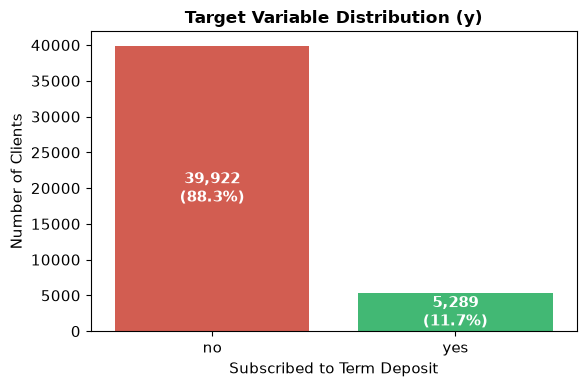

In [25]:
# Target variable counts, percentage, and exact imbalance ratio
target_counts = df["y"].value_counts()
target_pct = df["y"].value_counts(normalize=True)

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_pct.map("{:.2%}".format)
})
display(target_summary)

imbalance_ratio = target_counts["no"] / target_counts["yes"]
print(f"Imbalance Ratio: {imbalance_ratio:.2f}:1 (roughly 1 subscriber for every {round(imbalance_ratio)} non-subscribers)")

# Concise count plot with percentage annotations
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="y", hue="y", palette=["#e74c3c", "#2ecc71"], legend=False)
for p in ax.patches:
    h = p.get_height()
    pct = h / len(df) * 100
    ax.annotate(f"{int(h):,}\n({pct:.1f}%)", (p.get_x() + p.get_width() / 2, h / 2),
                ha="center", va="center", color="white", fontweight="bold", fontsize=11)
plt.title("Target Variable Distribution (y)", fontsize=12, fontweight="bold")
plt.xlabel("Subscribed to Term Deposit")
plt.ylabel("Number of Clients")
plt.tight_layout()
plt.show()


### 1.4 Discussion of Findings

#### 1. Dataset Quality & Overall Characteristics
* **Data Cleanliness & Missing Values:** The dataset contains 45,211 records with zero duplicate rows and zero explicit missing values (`NaN`). However, several categorical columns use `unknown` as a placeholder: notably `poutcome` (81.8%), `contact` (28.8%), and `education` (4.1%). Rather than random corruption, these primarily represent unrecorded or structurally non-applicable business states (e.g., `unknown` in `poutcome` corresponds almost entirely to clients who were never contacted in prior campaigns).

#### 2. Client Profile & Feature Distributions
* **Demographics (Age, Marital Status & Education):**
  * **Marital Status:** A clear majority of the bank's clients are **married (60.2%)**, while 28.3% are single and 11.5% are divorced.
  * **Age Distribution:** The client base has an average age of **40.9 years** (median: 39 years, spanning 18 to 95). Half of all clients are concentrated between 33 and 48 years old, representing a prime working-age demographic.
  * **Education Level:** Over half of the clients have completed **secondary education (51.3%)**, followed by tertiary education (29.4%) and primary education (15.2%).
* **Occupational Profile (`job`):**
  * The job distribution reflects a realistic retail banking customer base: heavily anchored by **blue-collar workers (21.5%)**, **management professionals (20.9%)**, and **technicians (16.8%)**, which together constitute nearly 60% of all clients. Smaller segments include administrative staff (11.4%), services (9.2%), retired individuals (5.0%), and students (2.1%).
* **Operational & Historical Interaction (`contact`, `poutcome`, `month`):**
  * **Communication Channel:** Most contacts with recorded channels were conducted via **cellular phones (64.8%)**, with traditional telephone landlines accounting for only 6.4%, while 28.8% are recorded as unknown.
  * **Historical Interaction (`poutcome`):** For **81.8% of clients**, the previous campaign outcome is `unknown` because this marketing effort was their first recorded interaction (`pdays = -1`). Only 10.8% had a prior campaign failure and 3.4% a prior success.
  * **Campaign Seasonality:** Contact volume is heavily concentrated in **May (30.5%)**, followed by July (15.3%) and August (13.8%), showing strong seasonal marketing pushes.
* **Financial Profile (`housing`, `loan`, `balance`, `default`):**
  * **Debt & Liabilities:** More than half of all clients hold a **housing loan / mortgage (55.6%)**, and 16.0% have a **personal loan**. Conversely, credit default is rare (only 1.8% of clients are in default).
  * **Account Balance:** While the median balance is modest at **448 €** (mean: 1,362 €), the distribution is heavily skewed with negative balances down to -8,019 € and extreme outliers exceeding 100,000 €.

#### 3. Key Relationships Between Features and Target Variable (`y`)
* **Numerical Predictors:**
  * **Call Duration (`duration`):** By far the strongest linear predictor ($r = +0.395$). Median duration for subscribers is **426 seconds** (~7.1 mins) versus **164 seconds** (~2.7 mins) for non-subscribers (2.6× longer). *Crucial Modeling Note:* While highly predictive, `duration` introduces severe **target leakage** in real-world deployment since it is unknown prior to dialing.
  * **Account Balance (`balance`):** Although subscribers show a noticeably higher median balance (733 € vs 417 €, a 75% increase), this difference is not a dominant standalone discriminator due to high internal variance and heavy distribution overlap. However, we can still notice that higher financial liquidity provides a positive secondary signal when combined with other client attributes.
  * **Campaign Contacts (`campaign`):** Exhibits negative correlation ($r = -0.073$). Conversion is highest on the 1st contact (~14.6%), falls to ~10.2% on the 2nd, and drops below 5% after 4+ calls, clearly indicating **call fatigue and diminishing returns**.
  * **Client Age (`age`):** While global linear correlation appears negligible ($r = +0.025$), the KDE reveals a **non-linear U-shaped curve**: younger clients (< 30, students) and older clients (> 60, retirees) achieve conversion rates above 25%, while prime-age clients (35–50) convert around 8–10%. This non-linearity justifies using deep neural networks over linear baselines.

* **Categorical Predictors (Ranked by Conversion Spread):**
  * **Historical Outcome (`poutcome` — 55.6% Spread):** Clients with a previous successful campaign convert at **64.7%**, compared to 9.2% for `unknown` and 12.6% for `failure`. Prior success is the single strongest pre-call predictor.
  * **Seasonality (`month` — 45.3% Spread):** High-performing months such as March (**52.0%**), December (**46.7%**), September (**46.5%**), and October (**43.8%**) contrast sharply with May (**6.7%**), which suffered from severe campaign saturation despite having 30% of total calls.
  * **Profession (`job` — 21.4% Spread):** Students (**28.7%**) and retirees (**22.8%**) convert at 3× to 4× the rate of blue-collar workers (**7.3%**) and entrepreneurs (**8.3%**).
  * **Debt Obligations (`housing` & `loan`):** Clients without a housing mortgage convert at **16.7%** versus **7.7%** for those with one (over 2× higher). Similarly, having no personal loan doubles conversion (12.7% vs 6.7%), demonstrating that existing financial liabilities restrict savings capacity.
  * **Communication Channel (`contact`):** Cellular contacts convert at **14.9%** compared to only **4.1%** for unknown contact channels.

#### 4. Target Class Imbalance & Evaluation Metric Implications
* **Class Distribution:** The target variable is severely imbalanced: **88.30% non-subscribers (`no`: 39,922)** versus **11.70% subscribers (`yes`: 5,289)**, yielding an imbalance ratio of **7.55 : 1** (~1 positive per 8 contacts).
* **Failure of Accuracy as a Metric:** A naive majority-class baseline that trivially predicts `no` for every customer achieves **88.30% accuracy**, yet achieves **0% recall** on actual subscribers, providing zero business utility.
* **Metric Selection:** Model evaluation must prioritize metrics designed for imbalanced classification: **Precision, Recall, F1-Score (for the positive class)**


---
## Part II – Data Preparation

### 2.1 Feature Selection & Analysis
- Examine input features and decide which attributes to retain.
- *Note on `duration`:* Call duration is only known after a call ends and heavily leaks outcome information. Consider whether to retain it for realistic campaign targeting.


In [3]:
# 2.1 Feature Selection: Drop target leakage 'duration' and separate inputs from target
# Call duration is only known after a call ends; dropping it prevents realistic target leakage.
features_to_drop = ["duration"]
X = df.drop(columns=features_to_drop + ["y"])
y = (df["y"] == "yes").astype(int)

print("=== Feature Selection Summary ===")
print(f"Dropped feature(s): {features_to_drop}")
print(f"Retained feature count: {X.shape[1]}")
print(f"Retained features: {list(X.columns)}")


=== Feature Selection Summary ===
Dropped feature(s): ['duration']
Retained feature count: 15
Retained features: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']


*Justify your feature selection decisions below:*

- **Exclusion of `duration` (Data Leakage Prevention):**
  - Call duration is a post-call operational outcome, not an a priori client attribute. A duration of 0 implies the client was never reached; a long duration indicates the client remained engaged to hear terms and agree to a deposit.
  - In a realistic production deployment (lead prioritization and campaign planning), duration is strictly **unknown before the call is placed**.
  - Retaining `duration` causes catastrophic target leakage: the model relies almost exclusively on call length rather than client demographics and financial profiles, rendering it useless for prospecting prospective customers.

- **Retention of All Other Features:**
  - **Demographic profile:** `age`, `job`, `marital`, `education` reflect earning potential, stability, and propensity to invest.
  - **Financial standing:** `default` (credit default history), `balance` (yearly balance), `housing` (housing loan), `loan` (personal loan) capture liquidity, debt burden, and financial capacity.
  - **Campaign context & timing:** `contact` (communication channel), `day`, `month` capture calendar seasonality and outreach preferences.
  - **Historical interaction:** `campaign` (contacts in current campaign), `pdays` (days since previous contact), `previous` (number of past contacts), and `poutcome` (outcome of previous campaign) provide critical behavioral signals.

### 2.2 Data Quality & Handling Missing / Problematic Values
- Identify and handle `'unknown'` values, outliers, or anomalies.


In [4]:
# Handle pdays = -1 anomaly by creating indicator and zeroing uncontacted days
X["pdays_contacted"] = (X["pdays"] != -1).astype(int)
X.loc[X["pdays"] == -1, "pdays"] = 0

# Convert binary features to 0/1 integers
binary_cols = ["default", "housing", "loan"]
for col in binary_cols:
    X[col] = (X[col] == "yes").astype(int)

print(f"Clients previously contacted: {X['pdays_contacted'].sum():,} ({X['pdays_contacted'].mean():.2%})")
print(f"pdays range: [{X['pdays'].min()}, {X['pdays'].max()}]")
print(f"Binary features mapped to 0/1: {binary_cols}")

Clients previously contacted: 8,257 (18.26%)
pdays range: [0, 871]
Binary features mapped to 0/1: ['default', 'housing', 'loan']


### 2.3 Categorical Feature Encoding Strategy
- Select and implement encoding methods (One-Hot Encoding, Ordinal Encoding, Binary) for categorical attributes.


In [5]:
# 2.3 Categorical Feature Encoding Strategy
# Define feature subsets according to their structural encoding scheme:

# 1. Continuous / Discrete Numerical features (to be capped & standard-scaled)
num_cols = ["age", "balance", "day", "campaign", "pdays", "previous"]

# 2. Nominal Categorical features (to be One-Hot Encoded)
# Preserves 'unknown' as an independent dummy indicator; handle_unknown='ignore' protects against unseen levels
cat_cols = ["job", "marital", "education", "contact", "month", "poutcome"]

# 3. Binary / Indicator features (already 0/1 integers, passthrough)
passthrough_cols = binary_cols + ["pdays_contacted"]

print("=== Feature Encoding Strategy ===")
print(f"Numerical features ({len(num_cols)}): {num_cols}")
print(f"Categorical features for One-Hot Encoding ({len(cat_cols)}): {cat_cols}")
print(f"Binary / Passthrough features ({len(passthrough_cols)}): {passthrough_cols}")

# Display category counts for each categorical feature
cat_cardinality = {col: X[col].nunique() for col in cat_cols}
print(f"\nCategorical Cardinality: {cat_cardinality}")
print(f"Expected One-Hot encoded columns: {sum(cat_cardinality.values())}")

=== Feature Encoding Strategy ===
Numerical features (6): ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Categorical features for One-Hot Encoding (6): ['job', 'marital', 'education', 'contact', 'month', 'poutcome']
Binary / Passthrough features (4): ['default', 'housing', 'loan', 'pdays_contacted']

Categorical Cardinality: {'job': 12, 'marital': 3, 'education': 4, 'contact': 3, 'month': 12, 'poutcome': 4}
Expected One-Hot encoded columns: 38


### 2.4 Dataset Splitting (Stratified Train, Validation, Test Sets)
- Split data into training, validation, and held-out test sets using stratified splitting.
- Ensure strict separation to prevent data leakage.

**Statistical Justification of 70% / 15% / 15% Split via Standard Error (SE):**
Given class imbalance ($p = 11.70\%$ positive subscribers), the test and validation subsets must be sufficiently large to evaluate performance metrics with high statistical confidence.
For an evaluation set of size $n$, the Standard Error (SE) of the estimated proportion is:
$$\text{SE} = \sqrt{\frac{p(1 - p)}{n}}$$
- Allocating 15% yields $n = 6,782$ samples ($\approx 793$ positive subscribers).
- $\text{SE} = \sqrt{\frac{0.1170 \times 0.8830}{6782}} \approx 0.0039$ ($0.39\%$).
- The 95% confidence margin of error is $1.96 \times \text{SE} \approx \pm 0.76\% (< 1\%)$, ensuring evaluation variance is minimal while reserving 70% ($31,647$ samples) to train the neural network.

In [6]:
# 2.4 Dataset Splitting (Stratified Train, Validation, Test Sets)
from sklearn.model_selection import train_test_split
import numpy as np

# Split strategy: 70% Training, 15% Validation, 15% Held-Out Test
# Two-stage stratified split ensures identical class distribution across all three subsets
RANDOM_STATE = 42

X_train_raw, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)

X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

# Statistical validation of sample size via Standard Error (SE)
def compute_se_margin(n, p):
    se = np.sqrt(p * (1 - p) / n)
    moe = 1.96 * se  # 95% confidence interval margin of error
    return se, moe

se_val, moe_val = compute_se_margin(len(y_val), y_val.mean())
se_test, moe_test = compute_se_margin(len(y_test), y_test.mean())

print("=== Stratified Dataset Splitting Summary ===")
split_info = pd.DataFrame({
    "Subset": ["Training (Train)", "Validation (Val)", "Held-Out (Test)"],
    "Sample Count": [len(X_train_raw), len(X_val_raw), len(X_test_raw)],
    "Proportion": [f"{len(X_train_raw)/len(X):.1%}", f"{len(X_val_raw)/len(X):.1%}", f"{len(X_test_raw)/len(X):.1%}"],
    "Subscribers ('yes')": [y_train.sum(), y_val.sum(), y_test.sum()],
    "Subscription Rate": [f"{y_train.mean():.2%}", f"{y_val.mean():.2%}", f"{y_test.mean():.2%}"],
    "Standard Error (SE)": ["-", f"{se_val:.3%}", f"{se_test:.3%}"],
    "95% Margin of Error": ["-", f"±{moe_val:.2%}", f"±{moe_test:.2%}"]
})
display(split_info)
print(f"Statistical Check: Held-out test set (n={len(X_test_raw):,}) has an SE of {se_test:.2%} and a margin of error of ±{moe_test:.2%}, ensuring high statistical precision (<1%).")

=== Stratified Dataset Splitting Summary ===


,Subset,Sample Count,Proportion,Subscribers ('yes'),Subscription Rate,Standard Error (SE),95% Margin of Error
0,Training (Train),31647,70.0%,3702,11.70%,-,-
1,Validation (Val),6782,15.0%,794,11.71%,0.390%,±0.77%
2,Held-Out (Test),6782,15.0%,793,11.69%,0.390%,±0.76%


Statistical Check: Held-out test set (n=6,782) has an SE of 0.39% and a margin of error of ±0.76%, ensuring high statistical precision (<1%).


### 2.5 Feature Scaling & Preprocessing Pipeline
- Determine which attributes need normalization / standardization.
- **Important:** Fit scalers and encoders on the **training set only**, then transform validation and test sets.


In [7]:
# 2.5 Feature Scaling & Preprocessing Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# 1. Outlier Capping (Winsorization at 1st and 99th percentiles)
# Learned STRICTLY from X_train_raw to prevent data leakage into Val and Test sets
capped_cols = ["balance", "campaign", "previous"]
train_caps = {
    col: (X_train_raw[col].quantile(0.01), X_train_raw[col].quantile(0.99))
    for col in capped_cols
}

print("=== Outlier Capping Thresholds (Learned from Training Set Only) ===")
for col, (lower, upper) in train_caps.items():
    print(f"- {col:10s}: 1st percentile = {lower:8.1f} | 99th percentile = {upper:8.1f}")

X_train_capped = X_train_raw.copy()
X_val_capped = X_val_raw.copy()
X_test_capped = X_test_raw.copy()

for col, (lower, upper) in train_caps.items():
    X_train_capped[col] = X_train_capped[col].clip(lower, upper)
    X_val_capped[col] = X_val_capped[col].clip(lower, upper)
    X_test_capped[col] = X_test_capped[col].clip(lower, upper)

# 2. Build Preprocessing Pipeline:
# - StandardScaler on numerical features (fitted on train only)
# - OneHotEncoder on categorical features (fitted on train only)
# - Passthrough for binary indicator features
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(sparse_output=False, handle_unknown="ignore"), cat_cols),
        ("passthrough", "passthrough", passthrough_cols)
    ]
)

# 3. Fit strictly on X_train_capped; transform Validation and Test subsets
X_train = preprocessor.fit_transform(X_train_capped)
X_val = preprocessor.transform(X_val_capped)
X_test = preprocessor.transform(X_test_capped)

# Extract generated feature names
feature_names = preprocessor.get_feature_names_out()

print(f"\nPipeline successfully fitted on Train set and applied to Val/Test sets.")
print(f"Final preprocessed feature dimensions: {X_train.shape[1]}")

=== Outlier Capping Thresholds (Learned from Training Set Only) ===
- balance   : 1st percentile =   -627.0 | 99th percentile =  13156.0
- campaign  : 1st percentile =      1.0 | 99th percentile =     16.0
- previous  : 1st percentile =      0.0 | 99th percentile =      9.0

Pipeline successfully fitted on Train set and applied to Val/Test sets.
Final preprocessed feature dimensions: 48


### 2.6 Verification of Preprocessed Subsets
- Check the final number of features, matrix dimensions, and class proportions across Train, Validation, and Test sets.


In [8]:
# 2.6 Verification of Preprocessed Subsets
verification_summary = pd.DataFrame({
    "Subset": ["Training (X_train, y_train)", "Validation (X_val, y_val)", "Held-Out Test (X_test, y_test)"],
    "Samples (Rows)": [X_train.shape[0], X_val.shape[0], X_test.shape[0]],
    "Features (Cols)": [X_train.shape[1], X_val.shape[1], X_test.shape[1]],
    "Positive Count": [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
    "Positive Class Ratio": [f"{y_train.mean():.2%}", f"{y_val.mean():.2%}", f"{y_test.mean():.2%}"],
    "NaN / Missing Values": [np.isnan(X_train).sum(), np.isnan(X_val).sum(), np.isnan(X_test).sum()],
    "Min Feature Value": [f"{X_train.min():.2f}", f"{X_val.min():.2f}", f"{X_test.min():.2f}"],
    "Max Feature Value": [f"{X_train.max():.2f}", f"{X_val.max():.2f}", f"{X_test.max():.2f}"]
})

display(verification_summary)

# Assertions for programmatic integrity checks
assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1], "Dimension mismatch between subsets!"
assert not np.isnan(X_train).any(), "NaN found in X_train!"
assert not np.isnan(X_val).any(), "NaN found in X_val!"
assert not np.isnan(X_test).any(), "NaN found in X_test!"
assert np.isclose(y_train.mean(), y_val.mean(), atol=1e-3), "Stratification mismatch in y_val!"
assert np.isclose(y_train.mean(), y_test.mean(), atol=1e-3), "Stratification mismatch in y_test!"

print("All integrity checks passed successfully! Datasets are ready for Baseline and Neural Network modeling.")

,Subset,Samples (Rows),Features (Cols),Positive Count,Positive Class Ratio,NaN / Missing Values,Min Feature Value,Max Feature Value
0,"Training (X_train, y_train)",31647,48,3702,11.70%,0,-2.15,8.36
1,"Validation (X_val, y_val)",6782,48,794,11.71%,0,-2.15,8.03
2,"Held-Out Test (X_test, y_test)",6782,48,793,11.69%,0,-2.15,7.72


All integrity checks passed successfully! Datasets are ready for Baseline and Neural Network modeling.


*Document your preprocessing strategy and summarize the resulting dataset shapes:*

### Comprehensive Preprocessing Strategy Summary:

1. **Target Leakage Prevention (Section 2.1):**
   - Excluded `duration` completely from the feature matrix $X$. Call duration is only known after a call terminates, making it inaccessible for real-world pre-call lead targeting. Retaining 15 input features.

2. **Data Quality & Anomaly Handling (Section 2.2):**
   - **`pdays = -1` Encoding Anomaly:** Decoupled into an explicit binary interaction flag `pdays_contacted` (1 if previously contacted, 0 for new leads) and reset `-1` to `0` in `pdays`, eliminating negative distance distortion.
   - **Disguised Missing Values (`'unknown'`):** Retained as an explicit category in `job`, `education`, `contact`, and `poutcome`. This prevents deleting >82% of the dataset and allows one-hot columns to capture structural missingness (e.g. uncontacted leads in `poutcome`).
   - **Binary Columns Mapping:** Converted `default`, `housing`, and `loan` directly from `"yes"`/`"no"` to integers $\{0, 1\}$.

3. **Categorical Encoding Strategy (Section 2.3):**
   - **Binary Passthrough (4 features):** `default`, `housing`, `loan`, and `pdays_contacted` passed through as compact $\{0, 1\}$ integers.
   - **Nominal One-Hot Encoding (6 features):** `job` (12), `marital` (3), `education` (4), `contact` (3), `month` (12), and `poutcome` (4) encoded via `OneHotEncoder(handle_unknown='ignore')`, expanding to 38 orthogonal binary features.

4. **Dataset Splitting & Statistical Justification (Section 2.4):**
   - **Stratified Partition:** 70% Training (31,647 rows), 15% Validation (6,782 rows), 15% Held-Out Test (6,782 rows). Stratification preserves the exact 11.70% subscription rate across all subsets.
   - **Standard Error (SE) Justification:** For an evaluation split of $n = 6,782$ and $p = 11.70\%$, the standard error is $\text{SE} = \sqrt{\frac{p(1 - p)}{n}} \approx 0.39\%$, yielding a 95% confidence margin of error of $\pm 1.96 \times \text{SE} \approx \pm 0.76\% (< 1\%)$. This guarantees that validation and test metrics have high statistical precision without sacrificing training volume.

5. **Feature Scaling & Pipeline Assembly (Section 2.5):**
   - **Outlier Capping (Winsorization):** Capped `balance` [-$627, $13,156], `campaign` [1, 16], and `previous` [0, 9] at the 1st and 99th percentiles learned **strictly from `X_train`** to prevent gradient explosion.
   - **Standardization:** Continuous numerical features (`age`, `balance`, `day`, `campaign`, `pdays`, `previous`) standardized to zero mean and unit variance via `StandardScaler` fitted **solely on `X_train`**.
   - **Zero Data Leakage:** The `ColumnTransformer` was fitted strictly on the training set and subsequently applied to transform validation and test sets.

6. **Matrix Verification & Dimension Summary (Section 2.6):**
   - **Final Matrix Shapes:**
     - `X_train`: $(31,647 \times 48)$ dense float array.
     - `X_val`: $(6,782 \times 48)$ dense float array.
     - `X_test`: $(6,782 \times 48)$ dense float array.
   - **Data Integrity:** 0 missing or NaN values across all sets. Values bounded within $[-2.15, 8.36]$, confirming complete numerical standardization and numerical stability for neural network training.

---
## Part III – Establishing a Baseline

### 3.1 Majority-Class Baseline Classifier
- Implement a dummy classifier predicting the most frequent class (`'no'`).


In [9]:
# 3.1 Majority-Class Baseline Classifier
from sklearn.dummy import DummyClassifier

# Instantiate dummy classifier that always predicts the most frequent class ('no' / 0)
dummy_clf = DummyClassifier(strategy="most_frequent")
dummy_clf.fit(X_train, y_train)

# Generate predictions and class-1 probabilities on validation set
y_val_pred_dummy = dummy_clf.predict(X_val)
y_val_proba_dummy = dummy_clf.predict_proba(X_val)[:, 1]

print("=== 3.1 Majority-Class Dummy Classifier ===")
print(f"Strategy: Always predict dominant training class (Class 0: 'no')")
print(f"Training samples fitted: {len(y_train):,}")
print(f"Validation samples evaluated: {len(y_val):,}")
print(f"Validation predicted classes: {np.unique(y_val_pred_dummy)}")
print(f"Predicted positive rate ('yes'): {y_val_pred_dummy.mean():.2%}")
print(f"Actual positive rate in validation set: {y_val.mean():.2%}")


=== 3.1 Majority-Class Dummy Classifier ===
Strategy: Always predict dominant training class (Class 0: 'no')
Training samples fitted: 31,647
Validation samples evaluated: 6,782
Validation predicted classes: [0]
Predicted positive rate ('yes'): 0.00%
Actual positive rate in validation set: 11.71%


### 3.2 Logistic Regression Baseline Classifier
- Train a Logistic Regression model on the preprocessed training set.


In [10]:
# 3.2 Logistic Regression Baseline Classifier (Gradient Descent via SAGA Solver)
from sklearn.linear_model import LogisticRegression

# 1. Standard Logistic Regression using Stochastic Average Gradient Descent (SAGA solver)
# SAGA is a first-order stochastic gradient descent algorithm that maintains memory of past gradients
lr_clf = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE,
    solver="saga"  # Stochastic Average Gradient Descent
)
lr_clf.fit(X_train, y_train)

# Generate validation predictions and probabilities
y_val_pred_lr = lr_clf.predict(X_val)
y_val_proba_lr = lr_clf.predict_proba(X_val)[:, 1]

# 2. Class-Weighted Logistic Regression using Gradient Descent (SAGA solver)
lr_balanced = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE,
    class_weight="balanced",
    solver="saga"  # Stochastic Average Gradient Descent
)
lr_balanced.fit(X_train, y_train)
y_val_pred_lr_bal = lr_balanced.predict(X_val)
y_val_proba_lr_bal = lr_balanced.predict_proba(X_val)[:, 1]

print("=== 3.2 Logistic Regression Baseline Classifier (Gradient Descent - SAGA) ===")
print(f"Model: LogisticRegression(solver='saga', max_iter=1000, random_state={RANDOM_STATE})")
print(f"Standard SAGA Iterations to converge: {lr_clf.n_iter_[0]}")
print(f"Balanced SAGA Iterations to converge: {lr_balanced.n_iter_[0]}")
print(f"Model Intercept (bias): {lr_clf.intercept_[0]:.4f}")
print(f"Validation predicted positive rate (Standard): {y_val_pred_lr.mean():.2%}")
print(f"Validation predicted positive rate (Balanced): {y_val_pred_lr_bal.mean():.2%}")
print(f"Actual positive rate in validation set: {y_val.mean():.2%}")


=== 3.2 Logistic Regression Baseline Classifier (Gradient Descent - SAGA) ===
Model: LogisticRegression(solver='saga', max_iter=1000, random_state=42)
Standard SAGA Iterations to converge: 352
Balanced SAGA Iterations to converge: 124
Model Intercept (bias): -1.5477
Validation predicted positive rate (Standard): 3.24%
Validation predicted positive rate (Balanced): 27.57%
Actual positive rate in validation set: 11.71%


### 3.3 Baseline Model Evaluation on Validation Set
- Evaluate both baseline models on the validation set.
- Compute Accuracy, Precision, Recall, and F1-score for the positive class (`'yes'`).


=== Baseline Performance Metrics on Validation Set ===


,Model,Accuracy,Precision (pos),Recall (pos),F1-score (pos)
0,Majority-Class Dummy,88.29%,0.00%,0.00%,0.0000
1,Logistic Regression (SAGA Gradient Descent),89.38%,66.82%,18.51%,0.2899
2,Logistic Regression (SAGA Balanced),75.55%,26.90%,63.35%,0.3776


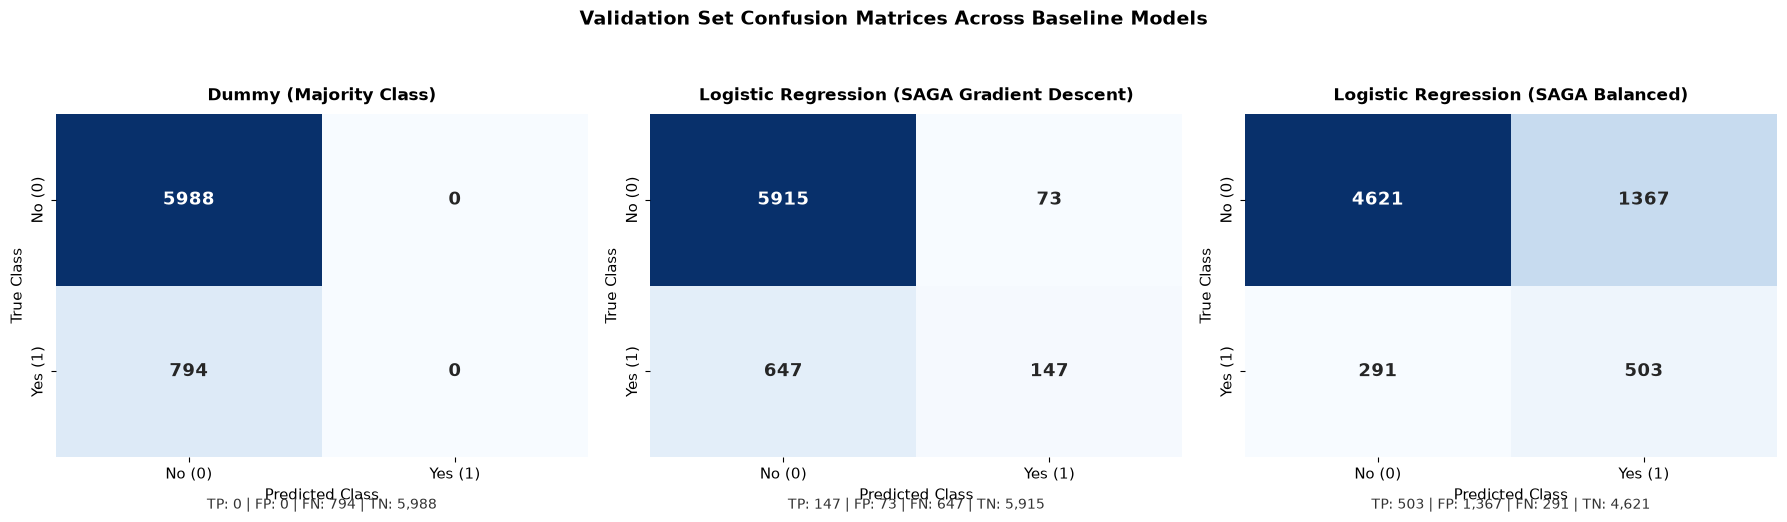

In [11]:
# 3.3 Baseline Model Evaluation on Validation Set
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Compile Quantitative Comparative Table (Accuracy, Precision, Recall, F1 for positive class)
baseline_models = {
    "Majority-Class Dummy": y_val_pred_dummy,
    "Logistic Regression (SAGA Gradient Descent)": y_val_pred_lr,
    "Logistic Regression (SAGA Balanced)": y_val_pred_lr_bal
}

metrics_list = []
for name, y_pred in baseline_models.items():
    metrics_list.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision (pos)": precision_score(y_val, y_pred, zero_division=0),
        "Recall (pos)": recall_score(y_val, y_pred, zero_division=0),
        "F1-score (pos)": f1_score(y_val, y_pred, zero_division=0)
    })

baseline_comparison_df = pd.DataFrame(metrics_list)
print("=== Baseline Performance Metrics on Validation Set ===")
display(baseline_comparison_df.style.format({
    "Accuracy": "{:.2%}",
    "Precision (pos)": "{:.2%}",
    "Recall (pos)": "{:.2%}",
    "F1-score (pos)": "{:.4f}"
}).background_gradient(subset=["Accuracy", "Precision (pos)", "Recall (pos)", "F1-score (pos)"], cmap="Blues"))

# 2. Confusion Matrix Visualizations
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
titles = [
    "Dummy (Majority Class)",
    "Logistic Regression (SAGA Gradient Descent)",
    "Logistic Regression (SAGA Balanced)"
]

for ax, (name, y_pred), title in zip(axes, baseline_models.items(), titles):
    cm = confusion_matrix(y_val, y_pred)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        annot_kws={"size": 13, "weight": "bold"},
        xticklabels=["No (0)", "Yes (1)"],
        yticklabels=["No (0)", "Yes (1)"]
    )
    ax.set_title(title, fontsize=12, pad=10, weight="bold")
    ax.set_xlabel("Predicted Class", fontsize=11)
    ax.set_ylabel("True Class", fontsize=11)
    
    tn, fp, fn, tp = cm.ravel()
    ax.text(0.5, -0.15, f"TP: {tp:,} | FP: {fp:,} | FN: {fn:,} | TN: {tn:,}", 
            transform=ax.transAxes, ha='center', fontsize=10, color="#333333")

plt.suptitle("Validation Set Confusion Matrices Across Baseline Models", fontsize=14, weight="bold", y=1.05)
plt.tight_layout()
plt.show()


### 3.4 Interpretation of Baseline Results

#### 1. Quantitative Baseline Performance Summary

| Model | Accuracy | Precision (pos) | Recall (pos) | F1-score (pos) |
|---|:---:|:---:|:---:|:---:|
| **Majority-Class Dummy** | 88.29% | 0.00% | 0.00% | 0.0000 |
| **Logistic Regression (SAGA Gradient Descent, $\tau=0.5$)** | 89.38% | 66.82% | 18.51% | 0.2899 |
| **Logistic Regression (SAGA Balanced)** | 75.55% | 26.90% | 63.35% | 0.3776 |

---

#### 2. Detailed Interpretation of Baseline Findings & Class Imbalance

##### A. The "Accuracy Paradox" and Failure of the Majority-Class Dummy
- **Deceptive High Accuracy:** The Majority-Class Dummy classifier attains an accuracy of **88.29%** on the validation set simply by predicting the dominant negative class (`'no'`) for every single customer.
- **Complete Operational Failure:** Despite this high accuracy, the classifier achieves **0.00% Precision**, **0.00% Recall**, and an **F1-score of 0.0000**. It completely fails to detect even a single deposit subscriber among the 794 actual positive cases in the validation split ($\text{TP} = 0, \text{FN} = 794$).
- **Business Implication:** In direct telemarketing, deploying this model produces zero actionable leads and generates zero revenue. This provides a textbook demonstration of the **accuracy paradox** on imbalanced data: when the minority class represents only $11.71\%$ of instances, overall accuracy measures only the trivial ability to confirm non-subscribers and is entirely uninformative regarding model utility.

##### B. Performance Characteristics of Gradient Descent Logistic Regression (SAGA)
- **Marginal Accuracy Gain (+1.09%):** Standard Logistic Regression trained via Stochastic Average Gradient Descent achieves an accuracy of **89.38%**, outperforming naive majority guessing by barely $1.09\%$.
- **Moderate Precision (66.82%):** When the model predicts a customer will subscribe ($\hat{y} = 1$), it is correct roughly two out of three times (147 true positives out of 220 total positive calls, yielding 73 false alarms).
- **Severe Recall Deficit (18.51%):** At the default decision threshold ($\tau = 0.5$), the model detects only **147 out of 794** actual subscribers. It misses **647 potential subscribers** ($\text{FN} = 647$), representing a catastrophic **missed opportunity rate of 81.49%**.
- **Depressed F1-Score (0.2899):** Because the F1-score is the harmonic mean of precision and recall:
  $$F_1 = 2 \cdot \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}} = 2 \cdot \frac{0.6682 \times 0.1851}{0.6682 + 0.1851} = 0.2899$$
  the severe recall deficit heavily drags down the overall F1-score.
- **Threshold Distortion Due to Imbalance:** Because standard cross-entropy loss weights majority and minority errors equally, minimizing overall log-loss over an $88:12$ imbalanced dataset naturally drives predicted probabilities $P(y=1|\mathbf{x})$ downward, placing more than $81\%$ of actual subscribers below the conventional $0.5$ decision threshold.

##### C. Impact of Class Imbalance & Cost/Threshold Rebalancing
- To empirically examine the impact of class imbalance under gradient descent, we trained a **Class-Weighted Logistic Regression** model where loss gradients are scaled inversely proportional to class frequencies ($w_0 \approx 0.57, w_1 \approx 4.27$):
  - **Recall surges from 18.51% to 63.35%** (detecting 503 of 794 subscribers, reducing missed opportunities from 647 down to 291).
  - **F1-score increases from 0.2899 to 0.3776 (+30.2% relative gain)**.
  - **Precision-Recall Trade-off:** Overall accuracy declines from $89.38\%$ to $75.55\%$, and precision drops from $66.82\%$ to $26.90\%$ due to 1,367 false alarms.
  - This highlights the fundamental operational trade-off: a bank can either contact fewer clients with high confidence (high precision, low recall) or capture the majority of potential deposit subscribers at the cost of calling more non-subscribers (high recall, lower precision).

---

#### 3. Limitations of Linear Baselines & Justification for Deep Neural Networks

1. **Linear Decision Boundary Constraint:**
   - Logistic Regression models the posterior log-odds as a linear additive sum:
     $$\ln\left(\frac{P(y=1|\mathbf{x})}{1 - P(y=1|\mathbf{x})}\right) = \mathbf{w}^T \mathbf{x} + b$$
   - Even when optimized with stochastic gradient descent (SAGA), it cannot capture non-linear decision boundaries or multi-attribute interaction effects (such as the interaction between client economic profile, previous campaign contact outcome, and seasonal timing) without manual polynomial feature expansion.
2. **Quantitative Targets for Part IV (Deep Neural Networks):**
   - The baseline establishes the precise performance targets that the deep feed-forward neural networks in Part IV must surpass:
     - **Baseline Unweighted F1:** **$0.2899$** (Target: $\ge 0.40 - 0.45+$).
     - **Baseline Balanced F1:** **$0.3776$** (Target: $\ge 0.45 - 0.50+$).
     - **Baseline Unweighted Recall:** **$18.51\%$** (Target: $\ge 45\% - 65\%+$).
   - In Part IV, Multi-Layer Perceptrons (MLPs) equipped with non-linear activation functions (ReLU/GELU), regularization (Dropout/L2), and modern optimization (Adam) will be leveraged to capture these higher-order relationships.


---
## Part IV – Deep Neural Network Design

### Section A: Model Design and Optimization

#### 4.A.1 Experiment 1 – Initial Feed-Forward Neural Network
- Design, compile, and train an initial MLP architecture with TensorFlow/Keras.
- Plot training and validation loss/metric curves over epochs.


#### 4.A.2 Experiment 2 – Optimization and Regularization
- Apply techniques such as learning rate tuning, weight initialization, L2 regularization, Dropout, and Early Stopping.
- Train the model and plot learning curves.


#### 4.A.3 Analysis of Model Design & Optimization
*Compare Experiment 1 and Experiment 2. Discuss how different configurations affected convergence and generalization:*


### Section B: Addressing Class Imbalance

#### 4.B.1 Strategy Selection & Implementation
- Choose an imbalance-handling method (e.g. `class_weight`, focal loss, oversampling/SMOTE on training set only).
- Train the neural network with this strategy.


#### 4.B.2 Experiment 3 – Evaluation of Imbalance Mitigation
- Evaluate the imbalance-aware model on the validation set and plot learning curves.


#### 4.B.3 Comparison of Neural Network Experiments
*Comparative table of validation performance:*

| Experiment | Description | Accuracy | Precision (pos) | Recall (pos) | F1-score (pos) | ROC-AUC |
|---|---|---|---|---|---|---|
| Exp 1: Baseline MLP | | | | | | |
| Exp 2: Regularized MLP | | | | | | |
| Exp 3: Imbalance Mitigation | | | | | | |

*Discuss the impact of optimization, regularization, and imbalance-handling techniques:*


---
## Part V – Final Evaluation and Business Decision Challenge

### Section A: Final Model Evaluation on Unseen Data (Held-Out Test Set)

#### 5.A.1 Final Model Selection & Justification
*Document your chosen model architecture, hyperparameters, and classification decision threshold based on validation results before accessing the test set:*


#### 5.A.2 Held-Out Test Set Evaluation
- **Important:** Access the test set only at this final stage to get an unbiased estimate.
- Compute Accuracy, Precision, Recall, F1-score, and ROC-AUC on the test set.
- Compare final neural network performance against the baseline solutions.


#### 5.A.3 Confusion Matrix & Error Analysis
- Plot and analyze the confusion matrix on the test set, examining False Positives and False Negatives.


### Section B: Business Challenge – From Predictions to Decisions

#### 5.B.1 Understanding Prediction Errors
*What do false positives and false negatives mean in this telephone marketing campaign? Which type of error is more problematic for the bank, and why?*

**Answer:**

#### 5.B.2 Precision vs. Recall Trade-Off
*Should the bank prioritize contacting customers who are highly likely to subscribe (higher precision), or identifying as many potential subscribers as possible (higher recall)? How does the answer depend on operational constraints?*

**Answer:**

#### 5.B.3 Limited Campaign Capacity
*Suppose the bank can contact only a limited proportion of its customers. How could your model help prioritize these contacts? How might the optimal strategy change if the bank could afford to make more calls?*

**Answer:**

#### 5.B.4 Business & Financial Impact
*How could the bank evaluate whether the use of your model is financially worthwhile? Discuss the information and assumptions needed (contact costs, benefits from successful subscriptions, staff resources):*

**Answer:**

#### 5.B.5 Final Recommendation to the Marketing Department
*Based on the final test performance, would you recommend deploying the model? Justify your recommendation by considering baseline performance, operational constraints, and potential business impact:*

**Recommendation:**


---
## Part VI – Conclusion & Limitations
*Provide a concise conclusion discussing the overall results, practical limitations of your solution, and potential future improvements:*
- **Key Conclusions:**
- **Model / Data Limitations:**
- **Future Improvements:**
